# Session 4: Variance, Covariance, Joint Distributions

*ECE 225A, Module 01 (Probability Review), slides 55-69*

Session 3 summarized a random variable by one number, its mean. This session adds a second summary, the **variance**, which measures how far the variable typically lands from its mean, together with its square root, the **standard deviation**. It then moves from one random variable to two. A **joint distribution** describes a pair, the **covariance** measures whether the two tend to move together, and the **correlation coefficient** rescales the covariance into a unit-free number between $-1$ and $1$. Two facts come up again and again: independence implies zero covariance (but not the other way around), and the variances of independent variables add.

## Learning objectives

After this session you should be able to:

1. Compute a variance both from the definition $E[(X - \mu)^2]$ and from the shortcut $E[X^2] - \mu^2$, and take its square root to get the standard deviation.
2. Derive the Bernoulli variance $p(1 - p)$ and explain why it is largest at $p = 1/2$.
3. Find the mean, variance, and standard deviation of $aX + b$ without working out its distribution.
4. Read a joint PMF from a table or from a uniform distribution over a support, and find its marginals.
5. Compute a covariance two ways and use its properties (symmetry, shift invariance, bilinearity).
6. Explain why independence implies zero covariance, and build a pair of variables that are uncorrelated but dependent.
7. Find $V(X + Y)$ from the two variances and the covariance.
8. Compute a correlation coefficient, use its invariance to units, and prove that $\lvert\rho\rvert \le 1$.

## Prerequisites

- Expectation, LOTUS $E[g(X)] = \sum_x g(x)\,p(x)$, and linearity of expectation (Session 3).
- The PMF and CDF of a discrete random variable, and the Bernoulli distribution $B_p$ (Session 3).
- Independence of events, $P(A \cap B) = P(A)\,P(B)$ (Session 2), and the law of total probability (Session 3).

In [1]:
from fractions import Fraction
from itertools import product
from math import sqrt

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

rng = np.random.default_rng(225)

BLUE, ORANGE, INK, MUTED, FAINT, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")


def E(pmf, g=lambda w: w):
    # LOTUS: E[g] = sum of g(w) p(w) over the outcomes w listed in the PMF.
    return sum((g(w) * p for w, p in pmf.items()), Fraction(0))

## 1. Variance and standard deviation (slides 55-56)

**Intuition.** The mean says where a distribution balances, but not how far its values typically fall from that point. A fair die, a die with faces 3, 3, 3, 4, 4, 4, and a die with faces 1, 1, 1, 6, 6, 6 all have mean 3.5, yet they spread out very differently.

To measure spread, look at the deviation $X - \mu$ from the mean. Its average is useless: positive and negative deviations cancel exactly, since $E[X - \mu] = E[X] - \mu = 0$ for every $X$. Squaring removes the sign, and it also penalizes large deviations more than small ones.

**Formal definitions.** Let $\mu = E[X]$. The **variance** of $X$ is the expected squared deviation from the mean,

$$V(X) = E\big[(X - \mu)^2\big] = \sum_x (x - \mu)^2\, p(x),$$

also written $V[X]$, $\mathrm{Var}(X)$, $\sigma_X^2$, or just $V$. (The sum is LOTUS with $g(x) = (x - \mu)^2$.) The **standard deviation** (std) is the nonnegative square root,

$$\sigma_X = +\sqrt{V(X)}.$$

The variance is in squared units (dollars squared, if $X$ is in dollars). The std is back in the units of $X$, so it reads as a typical distance from the mean.

Like the mean, both are **constants**, not random, and both are **functionals of the distribution**: they depend only on the PMF of $X$, not on the experiment that produced it.

**Equivalent formula.** Expand the square and apply linearity, remembering that $\mu$ is a constant:

$$V(X) = E\big[X^2 - 2\mu X + \mu^2\big] = E[X^2] - 2\mu\,E[X] + \mu^2 = E[X^2] - \mu^2.$$

In words: the mean of the square minus the square of the mean. Since $V(X) \ge 0$, this also proves $E[X^2] \ge (E[X])^2$. Equality holds only when $V(X) = 0$, and because $V(X) = \sum_x (x - \mu)^2 p(x)$ is a sum of nonnegative terms, that forces $p(x) = 0$ for every $x \ne \mu$: a variable with zero variance is a constant (with probability 1).

**Example: a fair die.** These slides give no numerical example, so take a fair die, with $\mu = 7/2$.

| $x$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $x - \mu$ | $-5/2$ | $-3/2$ | $-1/2$ | $1/2$ | $3/2$ | $5/2$ |
| $(x - \mu)^2$ | $25/4$ | $9/4$ | $1/4$ | $1/4$ | $9/4$ | $25/4$ |

1. Definition: every value has probability $1/6$, so $V(X) = \frac{1}{6} \cdot \frac{25 + 9 + 1 + 1 + 9 + 25}{4} = \frac{70}{24} = \frac{35}{12} \approx 2.917$.
2. Shortcut: $E[X^2] = \frac{1 + 4 + 9 + 16 + 25 + 36}{6} = \frac{91}{6}$, so $V(X) = \frac{91}{6} - \frac{49}{4} = \frac{182 - 147}{12} = \frac{35}{12}$.
3. Std: $\sigma_X = \sqrt{35/12} \approx 1.708$. A roll typically lands about 1.7 pips from 3.5.

In [2]:
def Var(pmf, g=lambda w: w):
    # V = E[(g - mu)^2], straight from the definition.
    mu = E(pmf, g)
    return E(pmf, lambda w: (g(w) - mu) ** 2)


die = {x: Fraction(1, 6) for x in range(1, 7)}
mu = E(die)
show("E[X]                ", mu)
show("V(X), definition    ", Var(die))
show("V(X), E[X^2] - mu^2 ", E(die, lambda x: x * x) - mu ** 2)
print(f"std sigma_X: {sqrt(Var(die)):.6f}")

E[X]                : 7/2 = 3.500000
V(X), definition    : 35/12 = 2.916667
V(X), E[X^2] - mu^2 : 35/12 = 2.916667
std sigma_X: 1.707825


**Monte Carlo check.** Roll a million dice and compare the sample variance and sample std with the exact values.

In [3]:
rolls = rng.integers(1, 7, size=1_000_000)
print(f"V(X): simulated {rolls.var():.4f}   exact {float(Var(die)):.4f}")
print(f"std : simulated {rolls.std():.4f}   exact {sqrt(Var(die)):.4f}")

V(X): simulated 2.9189   exact 2.9167
std : simulated 1.7085   exact 1.7078


The three dice below all have mean 3.5 (dashed line). The shaded band covers $\mu \pm \sigma$. As the mass moves away from the mean, the variance grows from $1/4$ to $25/4$, and the band widens with it.

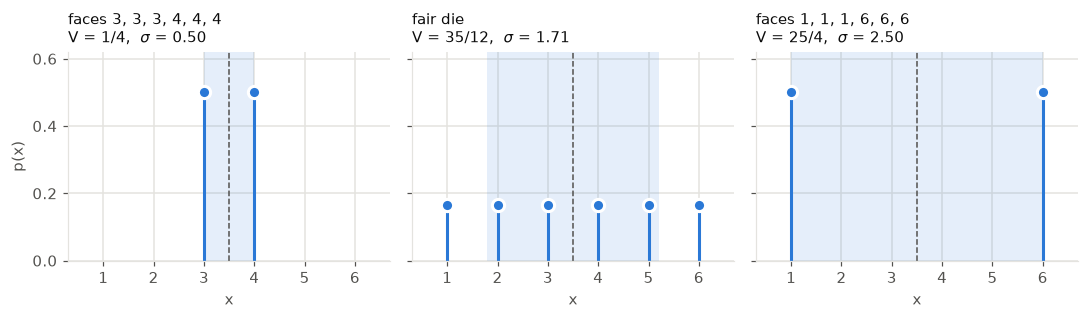

In [4]:
same_mean = {
    "faces 3, 3, 3, 4, 4, 4": {3: Fraction(1, 2), 4: Fraction(1, 2)},
    "fair die": die,
    "faces 1, 1, 1, 6, 6, 6": {1: Fraction(1, 2), 6: Fraction(1, 2)},
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, (name, pmf) in zip(axes, same_mean.items()):
    m, sd = float(E(pmf)), sqrt(Var(pmf))
    ax.axvspan(m - sd, m + sd, color=BLUE, alpha=0.12, lw=0)
    ax.axvline(m, color=MUTED, lw=1, ls="--")
    xs, ps = list(pmf), [float(p) for p in pmf.values()]
    ax.vlines(xs, 0, ps, color=BLUE, lw=2)
    ax.plot(xs, ps, "o", color=BLUE, ms=8, mec="white", mew=2)
    ax.set(xlim=(0.3, 6.7), ylim=(0, 0.62), xticks=range(1, 7), xlabel="x")
    ax.set_title(f"{name}\nV = {Var(pmf)},  $\\sigma$ = {sd:.2f}", color=INK, loc="left", fontsize=10)
axes[0].set_ylabel("p(x)")
plt.tight_layout()
plt.show()

## 2. Bernoulli variance (slide 57)

**Setup.** $X \sim B_p$ equals 1 with probability $p$ and 0 with probability $q = 1 - p$, and its mean is $\mu = p$ (Session 3).

**Route 1: the definition.** List each value with its deviation from the mean and the squared deviation.

| $x$ | $p(x)$ | $x - \mu$ | $(x - \mu)^2$ |
|---|---|---|---|
| 0 | $q$ | $0 - p = -p$ | $p^2$ |
| 1 | $p$ | $1 - p = q$ | $q^2$ |

The value 0 sits a distance $p$ below the mean, and the value 1 sits a distance $q$ above it. Weighting the squared distances by their probabilities,

$$V(X) = q \cdot p^2 + p \cdot q^2 = pq\,(p + q) = pq.$$

**Route 2: the shortcut.** Since $0^2 = 0$ and $1^2 = 1$, we have $X^2 = X$, so $E[X^2] = (1 - p) \cdot 0^2 + p \cdot 1^2 = p$ and

$$V(X) = E[X^2] - (E[X])^2 = p - p^2 = p(1 - p) = pq.$$

Both routes give $V(X) = pq$ and $\sigma_X = \sqrt{pq}$.

**Example: $B_{0.75}$.** Here $\mu = 0.75$. The value 0 is $0.75$ below the mean (probability $0.25$) and the value 1 is $0.25$ above it (probability $0.75$), so

$$V = 0.25 \cdot 0.75^2 + 0.75 \cdot 0.25^2 = 0.140625 + 0.046875 = 0.1875 = \tfrac{3}{16}, \qquad \sigma = \tfrac{\sqrt{3}}{4} \approx 0.433.$$

The rare value 0 is far from the mean, and the common value 1 is close to it.

In [5]:
def bernoulli(p):
    return {0: 1 - p, 1: p}


p = Fraction(3, 4)
q = 1 - p
show("definition  q p^2 + p q^2", q * p ** 2 + p * q ** 2)
show("shortcut    p - p^2      ", p - p ** 2)
show("helper      Var(B_0.75)  ", Var(bernoulli(p)))
print(f"std sqrt(pq) = {sqrt(p * q):.6f}")
assert all(Var(bernoulli(Fraction(k, 20))) == Fraction(k, 20) * (1 - Fraction(k, 20)) for k in range(21))

samples = (rng.random(1_000_000) < 0.75).astype(int)
print(f"B_0.75 variance: simulated {samples.var():.4f}   exact {float(p * q):.4f}")

definition  q p^2 + p q^2: 3/16 = 0.187500
shortcut    p - p^2      : 3/16 = 0.187500
helper      Var(B_0.75)  : 3/16 = 0.187500
std sqrt(pq) = 0.433013
B_0.75 variance: simulated 0.1872   exact 0.1875


How does the variance depend on $p$? Completing the square, $pq = p(1 - p) = \frac{1}{4} - \left(p - \frac{1}{2}\right)^2$, a downward parabola. It is 0 at $p = 0$ and $p = 1$, where $X$ is a constant, and largest, $1/4$, at $p = 1/2$, the least predictable coin. Swapping $p$ and $q$ does not change $pq$, so $B_{0.25}$ and $B_{0.75}$ have the same variance.

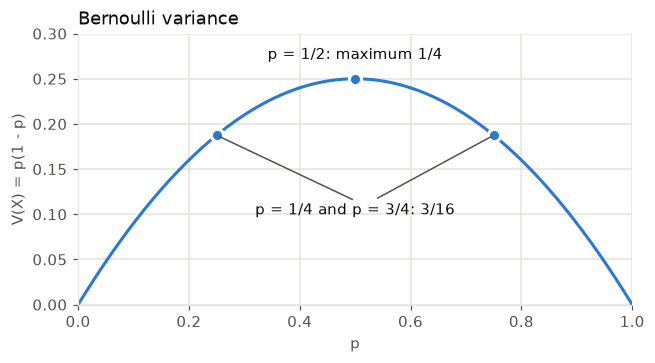

In [6]:
grid_p = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(grid_p, grid_p * (1 - grid_p), color=BLUE, lw=2)
for p0 in (0.25, 0.5, 0.75):
    ax.plot([p0], [p0 * (1 - p0)], "o", color=BLUE, ms=8, mec="white", mew=2)
ax.annotate("p = 1/2: maximum 1/4", xy=(0.5, 0.25), xytext=(0.5, 0.272), ha="center", color=INK)
ax.annotate("p = 1/4 and p = 3/4: 3/16", xy=(0.75, 0.1875), xytext=(0.5, 0.1), ha="center", color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.annotate("", xy=(0.25, 0.1875), xytext=(0.5, 0.115), arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set(xlim=(0, 1), ylim=(0, 0.3), xlabel="p", ylabel="V(X) = p(1 - p)")
ax.set_title("Bernoulli variance", color=INK, loc="left")
plt.show()

## 3. Affine transformations (slide 58)

**Intuition.** Adding a constant $b$ slides the whole distribution along the line. The mean moves by $b$, but every distance to the mean stays the same, so the spread does not change. Multiplying by $a$ stretches every distance to the mean by the factor $\lvert a \rvert$, so squared distances grow by $a^2$. A negative $a$ also mirrors the distribution, which does not change any distance.

**Formal statement.** For constants $a$ and $b$,

$$V(aX + b) = V(aX) = a^2\, V(X), \qquad \sigma_{aX + b} = \lvert a \rvert\, \sigma_X.$$

**Proof.** By linearity, $E[aX + b] = a\mu + b$, so the deviation of $aX + b$ from its own mean is $(aX + b) - (a\mu + b) = a(X - \mu)$, and $b$ cancels. Then

$$V(aX + b) = E\big[a^2 (X - \mu)^2\big] = a^2\, E\big[(X - \mu)^2\big] = a^2\, V(X).$$

Taking the nonnegative square root, $\sigma_{aX + b} = \sqrt{a^2}\,\sigma_X = \lvert a \rvert\,\sigma_X$.

| Operation | New variable | Mean | Variance | Std |
|---|---|---|---|---|
| Translation (add $b$) | $X + b$ | $E[X] + b$ | $V(X)$ | $\sigma_X$ |
| Scaling (multiply by $a$) | $aX$ | $a\,E[X]$ | $a^2\, V(X)$ | $\lvert a \rvert\, \sigma_X$ |
| Affine (both) | $aX + b$ | $a\,E[X] + b$ | $a^2\, V(X)$ | $\lvert a \rvert\, \sigma_X$ |

**Example.** A die game pays 4 dollars per pip and costs 15 dollars to play, so your net gain is $G = 4X - 15$. Without finding the PMF of $G$:

- $E[G] = 4 \cdot \frac{7}{2} - 15 = -1$ dollar;
- $V(G) = 4^2 \cdot \frac{35}{12} = \frac{140}{3} \approx 46.67$ dollars squared;
- $\sigma_G = 4 \cdot 1.708 \approx 6.83$ dollars.

The casino's gain is $-G = 15 - 4X$. Its mean is $+1$, but its variance and std equal yours, since $(-4)^2 = 16$ and $\lvert -4 \rvert = 4$.

In [7]:
G = lambda x: 4 * x - 15
show("E[G]          ", E(die, G))
show("V(G), direct  ", Var(die, G))
show("16 V(X)       ", 16 * Var(die))
show("V(-G), casino ", Var(die, lambda x: 15 - 4 * x))
print(f"std of G: {sqrt(Var(die, G)):.4f} = 4 * {sqrt(Var(die)):.4f}")

for a, b in [(1, 10), (3, 0), (-2, 5), (Fraction(1, 2), -7)]:
    assert E(die, lambda x: a * x + b) == a * E(die) + b
    assert Var(die, lambda x: a * x + b) == a ** 2 * Var(die)
print("E[aX + b] = a E[X] + b and V(aX + b) = a^2 V(X) hold exactly for every (a, b) tried")

E[G]          : -1 = -1.000000
V(G), direct  : 140/3 = 46.666667
16 V(X)       : 140/3 = 46.666667
V(-G), casino : 140/3 = 46.666667
std of G: 6.8313 = 4 * 1.7078
E[aX + b] = a E[X] + b and V(aX + b) = a^2 V(X) hold exactly for every (a, b) tried


## 4. Review: PMF and CDF (slides 59-60)

These two slides repeat Session 3 (Sections 6 and 7 of its notebook). Here is the short version, because the joint PMF in the next section extends the PMF to pairs.

- The PMF $p(x) = P(X = x)$ is the probability **of** $x$. The CDF $F(x) = P(X \le x) = \sum_{u \le x} p(u)$ is the probability **up to** $x$, and it is defined for every real $x$, even when $X$ is discrete.
- For $B_{0.7}$: $p(0) = 0.3$ and $p(1) = 0.7$, and $F$ is a staircase equal to 0 for $x < 0$, to $0.3$ on $[0, 1)$, and to 1 for $x \ge 1$.

In [8]:
def cdf(pmf, t):
    return sum((p for x, p in pmf.items() if x <= t), Fraction(0))


B07 = bernoulli(Fraction(7, 10))
print({t: str(cdf(B07, t)) for t in [-1, 0, 0.5, 1, 3]})

{-1: '0', 0: '3/10', 0.5: '3/10', 1: '1', 3: '1'}


## 5. Joint distributions (slide 61)

**Intuition.** Two random variables defined on the same experiment, such as the number of heads and the number of tails, or a person's height and weight, usually carry information about each other. Their separate PMFs cannot capture this. Questions such as "how likely is $X = Y$?" or "what is $E[XY]$?" need the probability of every **pair** of values. The joint distribution is the PMF idea applied to pairs.

**Formal definition.** If $X$ takes values in $\mathcal{X}$ and $Y$ in $\mathcal{Y}$, then the pair $(X, Y)$ takes values in the product $\mathcal{X} \times \mathcal{Y}$. The **joint PMF** is

$$p(x, y) = P\big((X, Y) = (x, y)\big) = P(X = x,\ Y = y).$$

| | One variable | Two variables |
|---|---|---|
| Values | $x \in \mathcal{X}$ | $(x, y) \in \mathcal{X} \times \mathcal{Y}$ |
| Distribution | PMF $p(x) = P(X = x)$ | joint PMF $p(x, y) = P(X = x, Y = y)$ |
| Rules | $p(x) \ge 0$ and $\sum_x p(x) = 1$ | $p(x, y) \ge 0$ and $\sum_{x, y} p(x, y) = 1$ |

**Marginals.** The events $\lbrace Y = y \rbrace$ partition the sample space, so by the law of total probability the PMF of $X$ alone is the joint PMF summed over $y$, and similarly for $Y$:

$$p_X(x) = \sum_y p(x, y), \qquad p_Y(y) = \sum_x p(x, y).$$

In a table with one row per $x$ and one column per $y$ (the layout the slides use), $p_X$ is the list of row sums and $p_Y$ is the list of column sums. They are written in the margins of the table, which is where the name **marginal distribution** comes from.

**LOTUS for pairs.** The expectation of any function of the pair is $E[g(X, Y)] = \sum_{x, y} g(x, y)\, p(x, y)$. For example, $E[XY] = \sum_{x, y} xy\, p(x, y)$.

**Running example (the table from slide 64).** $X, Y \in \lbrace 0, 1 \rbrace$ with

| | $y = 0$ | $y = 1$ | $p_X(x)$ |
|---|---|---|---|
| $x = 0$ | 0.5 | 0 | 0.5 |
| $x = 1$ | 0.2 | 0.3 | 0.5 |
| $p_Y(y)$ | 0.7 | 0.3 | 1 |

The row sums show $X \sim B_{0.5}$ and the column sums show $Y \sim B_{0.3}$.

In [9]:
X = lambda w: w[0]   # an outcome of the pair is w = (x, y)
Y = lambda w: w[1]


def pmf_of(joint, f):
    # PMF of f(X, Y): add the joint probabilities of all pairs that give the same value.
    out = {}
    for w, p in joint.items():
        out[f(w)] = out.get(f(w), 0) + p
    return dict(sorted(out.items()))


table = {(0, 0): Fraction(1, 2), (0, 1): Fraction(0),
         (1, 0): Fraction(1, 5), (1, 1): Fraction(3, 10)}
assert sum(table.values()) == 1 and min(table.values()) >= 0
print("p_X:", {x: str(p) for x, p in pmf_of(table, X).items()})
print("p_Y:", {y: str(p) for y, p in pmf_of(table, Y).items()})
show("E[XY] by LOTUS", E(table, lambda w: w[0] * w[1]))

p_X: {0: '1/2', 1: '1/2'}
p_Y: {0: '7/10', 1: '3/10'}
E[XY] by LOTUS: 3/10 = 0.300000


**The marginals do not determine the joint.** The next table has the same marginals, $B_{0.5}$ and $B_{0.3}$, but a different joint PMF: each cell is the product of its row total and its column total. (Section 11 will call such a table independent.) The joint PMF carries information that the two marginals lose.

In [10]:
product_table = {(x, y): px * py for x, px in pmf_of(table, X).items() for y, py in pmf_of(table, Y).items()}
print({w: str(p) for w, p in product_table.items()})
assert pmf_of(product_table, X) == pmf_of(table, X) and pmf_of(product_table, Y) == pmf_of(table, Y)
assert product_table != table

{(0, 0): '7/20', (0, 1): '3/20', (1, 0): '7/20', (1, 1): '3/20'}


## 6. Example: uniform distributions over a support (slide 62)

**Definition.** The **support** of a joint PMF is the set $S$ of pairs with positive probability. A joint PMF is **uniform over** $S$ if every pair in $S$ gets the same probability. Since the probabilities add to 1, each one is $1/\lvert S \rvert$, and a marginal probability counts support points in one row or column:

$$p(x, y) = \frac{1}{\lvert S \rvert} \ \text{ for } (x, y) \in S, \qquad P(X = x) = \frac{\#\lbrace y : (x, y) \in S \rbrace}{\lvert S \rvert}.$$

So the **element probability** is one over the size of the support, and a **marginal probability** is the number of support points in that line times the element probability. The marginals are usually *not* uniform.

**The four supports.** All four live in the grid $\lbrace 0, \dots, 4 \rbrace^2$ (25 cells), with $x$ indexing rows and $y$ indexing columns.

| Support | Shape | $\lvert S \rvert$ | Element probability | Marginal asked | Support points in that line | Answer |
|---|---|---|---|---|---|---|
| $\lbrace x = y \rbrace$ | the diagonal | 5 | $1/5$ | $P(X = 3)$ | row 3: only $(3, 3)$ | $1/5$ |
| $\lbrace x \le y \rbrace$ | the diagonal and the cells to its right | $5 + 4 + 3 + 2 + 1 = 15$ | $1/15$ | $P(X = 3)$ | row 3: $y = 3, 4$ | $2/15$ |
| $\lbrace \lvert x - y \rvert \le 1 \rbrace$ | the diagonal and its two neighbors | $5 + 4 + 4 = 13$ | $1/13$ | $P(Y = 3)$ | column 3: $x = 2, 3, 4$ | $3/13$ |
| $\lbrace \max(x, y) = 3 \rbrace$ | an L: row 3 and column 3, up to the corner | $4 + 4 - 1 = 7$ | $1/7$ | $P(Y = 3)$ | column 3: $x = 0, 1, 2, 3$ | $4/7$ |

For the last support, $\max(x, y) = 3$ means one coordinate is 3 and the other is at most 3. There are 4 such pairs with $x = 3$ and 4 with $y = 3$, and the corner $(3, 3)$ is in both groups, so $\lvert S \rvert = 7$.

In [11]:
grid = list(product(range(5), repeat=2))


def uniform(S):
    return {w: Fraction(1, len(S)) for w in S}


def draw(S):
    # Text picture of a support, laid out like the slide: rows are x = 0..4, columns are y = 0..4.
    print("       y: 0 1 2 3 4")
    for x in range(5):
        print(f"   x = {x}:", " ".join("#" if (x, y) in S else "." for y in range(5)))


supports = {
    "x = y": [w for w in grid if w[0] == w[1]],
    "x <= y": [w for w in grid if w[0] <= w[1]],
    "|x - y| <= 1": [w for w in grid if abs(w[0] - w[1]) <= 1],
    "max(x, y) = 3": [w for w in grid if max(w) == 3],
}
questions = [("x = y", X, "X"), ("x <= y", X, "X"), ("|x - y| <= 1", Y, "Y"), ("max(x, y) = 3", Y, "Y")]
answers = [Fraction(1, 5), Fraction(2, 15), Fraction(3, 13), Fraction(4, 7)]

for (name, f, label), answer in zip(questions, answers):
    S = supports[name]
    marginal = pmf_of(uniform(S), f)
    assert marginal[3] == answer
    print(f"support {name}: |S| = {len(S)}, element probability 1/{len(S)}, P({label} = 3) = {marginal[3]}")
    draw(set(S))

support x = y: |S| = 5, element probability 1/5, P(X = 3) = 1/5
       y: 0 1 2 3 4
   x = 0: # . . . .
   x = 1: . # . . .
   x = 2: . . # . .
   x = 3: . . . # .
   x = 4: . . . . #
support x <= y: |S| = 15, element probability 1/15, P(X = 3) = 2/15
       y: 0 1 2 3 4
   x = 0: # # # # #
   x = 1: . # # # #
   x = 2: . . # # #
   x = 3: . . . # #
   x = 4: . . . . #
support |x - y| <= 1: |S| = 13, element probability 1/13, P(Y = 3) = 3/13
       y: 0 1 2 3 4
   x = 0: # # . . .
   x = 1: # # # . .
   x = 2: . # # # .
   x = 3: . . # # #
   x = 4: . . . # #
support max(x, y) = 3: |S| = 7, element probability 1/7, P(Y = 3) = 4/7
       y: 0 1 2 3 4
   x = 0: . . . # .
   x = 1: . . . # .
   x = 2: . . . # .
   x = 3: # # # # .
   x = 4: . . . . .


## 7. Covariance (slide 63)

**Intuition.** Do $X$ and $Y$ tend to be above their means at the same time? Center both variables at their means, $\mu_X = E[X]$ and $\mu_Y = E[Y]$, and look at the product of the deviations, $(X - \mu_X)(Y - \mu_Y)$:

- it is **positive** when both are above their means or both are below (the upper-right and lower-left quadrants around the point $(\mu_X, \mu_Y)$);
- it is **negative** when one is above and the other is below (the other two quadrants).

Averaging this product over the joint distribution gives one number. Its sign says which kind of pair dominates, and its size says by how much. It measures how much $X$ and $Y$ vary together.

**Formal definition.** The **covariance** of $X$ and $Y$ is

$$\mathrm{Cov}(X, Y) = \sigma_{X,Y} = E\big[(X - \mu_X)(Y - \mu_Y)\big] = \sum_{x, y} (x - \mu_X)(y - \mu_Y)\, p(x, y).$$

Its unit is the unit of $X$ times the unit of $Y$.

**Equivalent formula.** Expand the product and apply linearity, treating $\mu_X$ and $\mu_Y$ as constants:

$$\mathrm{Cov}(X, Y) = E\big[XY - \mu_Y X - \mu_X Y + \mu_X \mu_Y\big] = E[XY] - \mu_Y \mu_X - \mu_X \mu_Y + \mu_X \mu_Y = E[XY] - \mu_X \mu_Y.$$

In words: the expectation of the product minus the product of the expectations. It mirrors $V(X) = E[X^2] - \mu^2$. The code checks that the two formulas agree exactly on the four supports of Section 6.

In [12]:
def Cov(joint, f=X, g=Y):
    # Cov(f, g) = E[(f - E f)(g - E g)], straight from the definition.
    mf, mg = E(joint, f), E(joint, g)
    return E(joint, lambda w: (f(w) - mf) * (g(w) - mg))


def Cov_shortcut(joint, f=X, g=Y):
    return E(joint, lambda w: f(w) * g(w)) - E(joint, f) * E(joint, g)


for name, S in supports.items():
    u = uniform(S)
    assert Cov(u) == Cov_shortcut(u)
    print(f"support {name:14s} Cov = {Cov(u)}")

support x = y          Cov = 2
support x <= y         Cov = 7/9
support |x - y| <= 1   Cov = 18/13
support max(x, y) = 3  Cov = -36/49


## 8. Example: covariance from a table, two ways (slides 64-65)

Return to the running table. From Section 5, $X \sim B_{0.5}$ and $Y \sim B_{0.3}$, so $\mu_X = 0.5$ and $\mu_Y = 0.3$.

**Take 1: the definition.** Sum $p(x, y)(x - \mu_X)(y - \mu_Y)$ over the four cells (LOTUS for pairs):

| $(x, y)$ | $p(x, y)$ | $x - 0.5$ | $y - 0.3$ | $p(x, y)(x - 0.5)(y - 0.3)$ |
|---|---|---|---|---|
| $(0, 0)$ | 0.5 | $-0.5$ | $-0.3$ | $0.5 \cdot 0.15 = 0.075$ |
| $(0, 1)$ | 0 | $-0.5$ | $0.7$ | $0$ |
| $(1, 0)$ | 0.2 | $0.5$ | $-0.3$ | $0.2 \cdot (-0.15) = -0.03$ |
| $(1, 1)$ | 0.3 | $0.5$ | $0.7$ | $0.3 \cdot 0.35 = 0.105$ |

$$\mathrm{Cov}(X, Y) = 0.075 + 0 - 0.03 + 0.105 = 0.15.$$

**Take 2: the shortcut.** Only the cell $(1, 1)$ has $xy \ne 0$, so $E[XY] = 0.3 \cdot 1 \cdot 1 = 0.3$ and

$$\mathrm{Cov}(X, Y) = E[XY] - \mu_X \mu_Y = 0.3 - 0.5 \cdot 0.3 = 0.3 - 0.15 = 0.15.$$

The covariance is positive: most of the probability sits on $(0, 0)$ and $(1, 1)$, where the two deviations have the same sign. Take 2 needs one product instead of four, which is why it is usually faster by hand.

In [13]:
show("Take 1, definition", Cov(table))
show("Take 2, shortcut  ", Cov_shortcut(table))

cells = list(table)
draws = rng.choice(len(cells), size=1_000_000, p=[float(table[c]) for c in cells])
tx, ty = np.array(cells)[draws].T   # simulated (X, Y) pairs from the table
print(f"Cov(X, Y): simulated {np.mean((tx - tx.mean()) * (ty - ty.mean())):.4f}   exact {float(Cov(table)):.4f}")

Take 1, definition: 3/20 = 0.150000
Take 2, shortcut  : 3/20 = 0.150000
Cov(X, Y): simulated 0.1501   exact 0.1500


## 9. The sign of the covariance and the shape of the support

The quadrant picture from Section 7 predicts the sign of a covariance from a picture of the support. Each panel below is a distribution that is uniform over the colored cells of the $5 \times 5$ grid. Here $x$ is on the horizontal axis and $y$ on the vertical axis, so "up and to the right" means both are larger (the slides draw tables with $x$ as rows instead). The dashed lines cross at the means $(\mu_X, \mu_Y)$. A cell is blue if its product of deviations $(x - \mu_X)(y - \mu_Y)$ is positive, orange if it is negative, and gray if it lies on a dashed line, where the product is 0. Every cell has the same probability, so the covariance is positive when the blue products outweigh the orange ones and negative in the opposite case.

The top row holds the three diagonal supports from slide 62. The bottom row holds a symmetric diamond, the "max = 3" support from slide 62, and the triangle $\lbrace x + y \le 4 \rbrace$, which is $\lbrace x \le y \rbrace$ turned upside down.

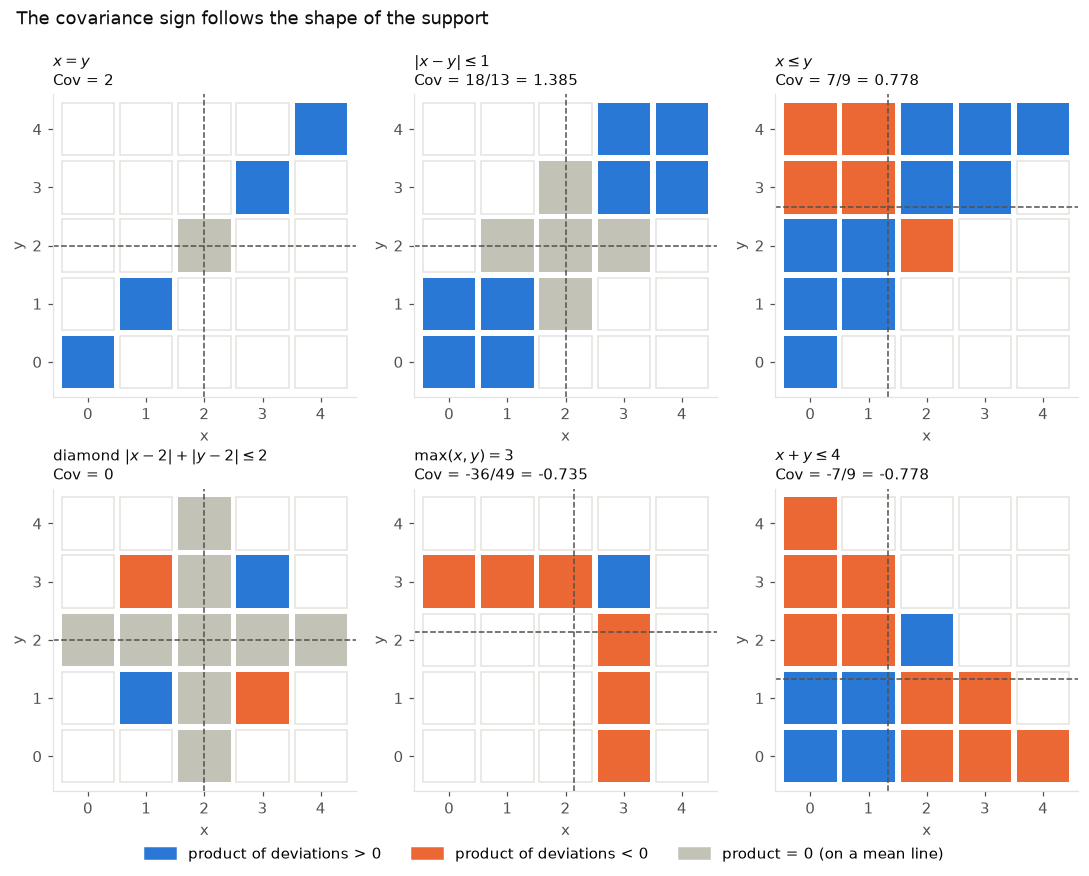

In [14]:
sign_supports = {
    "x = y": supports["x = y"],
    "|x - y| <= 1": supports["|x - y| <= 1"],
    "x <= y": supports["x <= y"],
    "diamond": [w for w in grid if abs(w[0] - 2) + abs(w[1] - 2) <= 2],
    "max(x, y) = 3": supports["max(x, y) = 3"],
    "x + y <= 4": [w for w in grid if w[0] + w[1] <= 4],
}
titles = {"x = y": r"$x = y$", "|x - y| <= 1": r"$|x - y| \leq 1$", "x <= y": r"$x \leq y$",
          "diamond": r"diamond $|x - 2| + |y - 2| \leq 2$", "max(x, y) = 3": r"$\max(x, y) = 3$",
          "x + y <= 4": r"$x + y \leq 4$"}


def exact_and_decimal(v):
    return str(v) if v.denominator == 1 else f"{v} = {float(v):.3f}"


fig, axes = plt.subplots(2, 3, figsize=(10, 8))
for ax, (name, S) in zip(axes.flat, sign_supports.items()):
    u = uniform(S)
    mx, my = E(u, X), E(u, Y)
    for x, y in grid:
        if (x, y) in u:
            d = (x - mx) * (y - my)   # exact, so the sign test is exact
            color = BLUE if d > 0 else ORANGE if d < 0 else FAINT
            ax.add_patch(Rectangle((x - 0.45, y - 0.45), 0.9, 0.9, fc=color, ec="none"))
        else:
            ax.add_patch(Rectangle((x - 0.45, y - 0.45), 0.9, 0.9, fc="none", ec=GRID, lw=1))
    ax.axvline(float(mx), color=MUTED, lw=1, ls="--")
    ax.axhline(float(my), color=MUTED, lw=1, ls="--")
    ax.set(xlim=(-0.6, 4.6), ylim=(-0.6, 4.6), xticks=range(5), yticks=range(5), aspect="equal",
           xlabel="x", ylabel="y")
    ax.grid(False)
    ax.set_title(f"{titles[name]}\nCov = {exact_and_decimal(Cov(u))}", color=INK, loc="left", fontsize=10)

handles = [Patch(color=BLUE, label="product of deviations > 0"),
           Patch(color=ORANGE, label="product of deviations < 0"),
           Patch(color=FAINT, label="product = 0 (on a mean line)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle("The covariance sign follows the shape of the support", color=INK, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0.04, 1, 0.97), h_pad=2.5)
plt.show()

Three things to notice:

- **Along a rising diagonal the covariance is positive.** The thinner the band around the line, the more the blue cells dominate.
- **"max = 3" has negative covariance**, even though it comes from the same slide as the diagonal examples. Most of its cells sit in the two arms, where one coordinate is 3 and the other is small: when one variable is large, the other tends to be small.
- **The diamond is perfectly balanced.** Turning it upside down ($y \to 4 - y$) maps every blue cell to an orange one, so the covariance is exactly 0. Yet $X$ and $Y$ are clearly related: if $X = 0$, then $Y$ must be 2. Section 11 returns to this.

Turning $\lbrace x \le y \rbrace$ upside down replaces $Y$ by $4 - Y$, and the covariance flips from $7/9$ to $-7/9$. Section 10 explains why.

## 10. Properties of covariance (slide 66)

Each property follows from the definition or the shortcut together with linearity of expectation. Write $\mu_X = E[X]$ and $\mu_Y = E[Y]$, and let $a, b, c, d$ be constants.

1. **Self covariance.** $\mathrm{Cov}(X, X) = E[X \cdot X] - \mu_X \mu_X = E[X^2] - \mu_X^2 = V(X)$. The variance is the covariance of a variable with itself.
2. **Symmetry.** $\mathrm{Cov}(X, Y) = E[(X - \mu_X)(Y - \mu_Y)] = E[(Y - \mu_Y)(X - \mu_X)] = \mathrm{Cov}(Y, X)$.
3. **Translation invariance.** The mean of $X + a$ is $\mu_{X + a} = \mu_X + a$, so the deviation $(X + a) - \mu_{X+a} = X - \mu_X$ does not change. Hence $\mathrm{Cov}(X + a, Y) = \mathrm{Cov}(X, Y)$: shifting a variable does not change how it moves with another one.
4. **Scaling linearity.** $\mathrm{Cov}(aX, Y) = E[aXY] - \mu_{aX}\,\mu_Y = a\,E[XY] - a\,\mu_X \mu_Y = a\,\mathrm{Cov}(X, Y)$.
5. **Affine transformations.** Combining 2, 3, and 4: $\mathrm{Cov}(aX + b,\, cY + d) = ac\,\mathrm{Cov}(X, Y)$. With $Y = X$, $c = a$, and $d = b$, this recovers $V(aX + b) = a^2 V(X)$.
6. **Additivity.** For a third variable $Z$, $\mathrm{Cov}(X + Z, Y) = E[(X + Z)Y] - (\mu_X + \mu_Z)\,\mu_Y = \mathrm{Cov}(X, Y) + \mathrm{Cov}(Z, Y)$.

Properties 2, 4, and 6 together say that covariance is **bilinear**: it expands like a product, $\mathrm{Cov}\left(\sum_i a_i X_i,\ \sum_j b_j Y_j\right) = \sum_{i, j} a_i b_j\, \mathrm{Cov}(X_i, Y_j)$. Section 12 uses this to expand $V(X + Y)$.

In [15]:
a, b, c, d = 3, -2, Fraction(-1, 2), 7
Z = lambda w: w[0] ** 2   # any third function of the outcome
for name, J in [("running table", table), ("max(x, y) = 3", uniform(supports["max(x, y) = 3"]))]:
    assert Cov(J, X, X) == Var(J, X)                                                    # 1. self covariance
    assert Cov(J, X, Y) == Cov(J, Y, X)                                                 # 2. symmetry
    assert Cov(J, lambda w: w[0] + a, Y) == Cov(J)                                      # 3. translation
    assert Cov(J, lambda w: a * w[0], Y) == a * Cov(J)                                  # 4. scaling
    assert Cov(J, lambda w: a * w[0] + b, lambda w: c * w[1] + d) == a * c * Cov(J)     # 5. affine
    assert Cov(J, lambda w: w[0] + Z(w), Y) == Cov(J) + Cov(J, Z, Y)                    # 6. additivity
    print(f"{name}: all six properties hold exactly; Cov(3X - 2, -Y/2 + 7) = ({a * c}) ({Cov(J)}) = {a * c * Cov(J)}")

running table: all six properties hold exactly; Cov(3X - 2, -Y/2 + 7) = (-3/2) (3/20) = -9/40
max(x, y) = 3: all six properties hold exactly; Cov(3X - 2, -Y/2 + 7) = (-3/2) (-36/49) = 54/49


## 11. Independent, uncorrelated, zero covariance (slide 67)

**Definitions.**

- $X$ and $Y$ are **uncorrelated** if their expectations multiply: $E[XY] = E[X]\,E[Y]$. By the shortcut formula, this is the same as $\mathrm{Cov}(X, Y) = 0$.
- $X$ and $Y$ are **independent**, written $X \perp\!\!\!\perp Y$, if every event about $X$ is independent of every event about $Y$. For discrete variables it is enough that the joint PMF factors into the marginals: $p(x, y) = p_X(x)\, p_Y(y)$ for **all** $x$ and $y$. This extends the independence of events from Session 2.

**Independent implies uncorrelated.** If the joint PMF factors, the double sum for $E[XY]$ splits into a product of two single sums:

$$E[XY] = \sum_{x, y} xy\, p_X(x)\, p_Y(y) = \Big(\sum_x x\, p_X(x)\Big)\Big(\sum_y y\, p_Y(y)\Big) = E[X]\,E[Y],$$

so $\mathrm{Cov}(X, Y) = E[XY] - E[X]\,E[Y] = 0$. The chain is: independent $\Rightarrow$ uncorrelated $\Leftrightarrow$ zero covariance.

**Contrapositive.** A nonzero covariance proves dependence. The running table has $\mathrm{Cov}(X, Y) = 0.15 \ne 0$, so $X$ and $Y$ are dependent. Indeed $p(0, 1) = 0$, while $p_X(0)\,p_Y(1) = 0.5 \cdot 0.3 = 0.15$.

**The converse is false.** Zero covariance does not imply independence. Covariance only detects a *linear* tendency (the quadrant balance of Section 9), and a strong dependence can be perfectly balanced.

*Counterexample 1.* Let $X$ be uniform on $\lbrace -1, 0, 1 \rbrace$ and let $Y = X^2$. Then $Y$ is a function of $X$, as dependent as it gets, yet

$$E[X] = 0, \qquad E[XY] = E[X^3] = \tfrac{1}{3}\big((-1)^3 + 0^3 + 1^3\big) = 0, \qquad \mathrm{Cov}(X, Y) = 0 - 0 \cdot E[Y] = 0.$$

Independence fails at a single cell: $P(X = 0, Y = 0) = P(X = 0) = 1/3$, but $P(X = 0)\,P(Y = 0) = \frac{1}{3} \cdot \frac{1}{3} = \frac{1}{9}$.

*Counterexample 2.* The uniform distribution over the diamond $\lbrace \lvert x - 2 \rvert + \lvert y - 2 \rvert \le 2 \rbrace$ from Section 9 has covariance 0 by symmetry, but $p(0, 0) = 0$ while $p_X(0)\,p_Y(0) = \frac{1}{13} \cdot \frac{1}{13} > 0$.

More generally, a uniform distribution over a support $S$ is independent exactly when $S$ is a full rectangle $A \times B$. If $X$ can be $x$ and $Y$ can be $y$, independence forces $p(x, y) = p_X(x)\,p_Y(y) > 0$, so no cell of $A \times B$ may be missing.

In [16]:
def independent(joint):
    # True when p(x, y) = p_X(x) p_Y(y) for every pair of values, including pairs missing from the support.
    pX, pY = pmf_of(joint, X), pmf_of(joint, Y)
    return all(joint.get((x, y), 0) == px * py for x, px in pX.items() for y, py in pY.items())


square = {(x, x * x): Fraction(1, 3) for x in (-1, 0, 1)}     # outcomes (X, Y) with Y = X^2
diamond = uniform(sign_supports["diamond"])

for name, J in [("running table", table), ("product table", product_table),
                ("Y = X^2", square), ("diamond", diamond)]:
    print(f"{name:14s} Cov = {str(Cov(J)):5s}  independent: {independent(J)}")
show("Y = X^2:  P(X = 0, Y = 0)  ", square[(0, 0)])
show("Y = X^2:  P(X = 0) P(Y = 0)", pmf_of(square, X)[0] * pmf_of(square, Y)[0])
show("diamond:  p(0, 0)          ", diamond.get((0, 0), Fraction(0)))
show("diamond:  p_X(0) p_Y(0)    ", pmf_of(diamond, X)[0] * pmf_of(diamond, Y)[0])

running table  Cov = 3/20   independent: False
product table  Cov = 0      independent: True
Y = X^2        Cov = 0      independent: False
diamond        Cov = 0      independent: False
Y = X^2:  P(X = 0, Y = 0)  : 1/3 = 0.333333
Y = X^2:  P(X = 0) P(Y = 0): 1/9 = 0.111111
diamond:  p(0, 0)          : 0 = 0.000000
diamond:  p_X(0) p_Y(0)    : 1/169 = 0.005917


**Monte Carlo check.** Simulate counterexample 1. The sample covariance is close to 0, yet knowing $X$ changes the distribution of $Y$ completely.

In [17]:
sx = rng.choice([-1, 0, 1], size=1_000_000)
sy = sx ** 2
print(f"sample Cov(X, Y) : {np.mean((sx - sx.mean()) * (sy - sy.mean())):+.4f}   exact 0")
print(f"P(Y = 0)         : {np.mean(sy == 0):.4f}   exact {1 / 3:.4f}")
print(f"P(Y = 0 | X = 0) : {np.mean(sy[sx == 0] == 0):.4f}   exact 1")

sample Cov(X, Y) : -0.0002   exact 0
P(Y = 0)         : 0.3337   exact 0.3333
P(Y = 0 | X = 0) : 1.0000   exact 1


## 12. Covariance and the variance of a sum (slide 68)

**Derivation.** Write the variance as a self covariance, expand with bilinearity (Section 10), and use symmetry:

$$V(X + Y) = \mathrm{Cov}(X + Y,\, X + Y) = \mathrm{Cov}(X, X) + \mathrm{Cov}(X, Y) + \mathrm{Cov}(Y, X) + \mathrm{Cov}(Y, Y) = V(X) + V(Y) + 2\,\mathrm{Cov}(X, Y).$$

This is the variance version of $(s + t)^2 = s^2 + t^2 + 2st$. The same expansion gives $V(X - Y) = V(X) + V(Y) - 2\,\mathrm{Cov}(X, Y)$ and, for $n$ variables, $V\left(\sum_i X_i\right) = \sum_i V(X_i) + 2\sum_{i < j} \mathrm{Cov}(X_i, X_j)$.

**Variances add for independent variables.** If $X \perp\!\!\!\perp Y$, then $\mathrm{Cov}(X, Y) = 0$ (Section 11), so

$$V(X + Y) = V(X) + V(Y).$$

The proof only uses zero covariance, so the same holds for uncorrelated variables. Compare with expectation: $E[X + Y] = E[X] + E[Y]$ always holds, but variances add only when the covariance vanishes. Standard deviations do not add even then: for independent variables, $\sigma_{X+Y} = \sqrt{\sigma_X^2 + \sigma_Y^2}$.

**Example: the running table.** The Bernoulli formula gives $V(X) = 0.5 \cdot 0.5 = 0.25$ and $V(Y) = 0.3 \cdot 0.7 = 0.21$, and $\mathrm{Cov}(X, Y) = 0.15$, so

$$V(X + Y) = 0.25 + 0.21 + 2(0.15) = 0.76, \qquad V(X - Y) = 0.25 + 0.21 - 2(0.15) = 0.16.$$

Direct check: $X + Y$ equals 0, 1, 2 with probabilities 0.5, 0.2, 0.3, so $E[X + Y] = 0.8$, $E[(X + Y)^2] = 0.2 + 4(0.3) = 1.4$, and $V(X + Y) = 1.4 - 0.64 = 0.76$. The positive covariance makes the sum more spread out, and the difference less spread out, than they would be for independent variables with the same marginals (both would be $0.46$).

**Example: two independent dice.** Each die has variance $35/12$, so the sum has variance $35/12 + 35/12 = 35/6 \approx 5.83$. Its std is $\sqrt{35/6} \approx 2.42$, not $2 \times 1.71 = 3.42$. (Session 5 applies the same idea to $n$ independent Bernoulli trials to get the binomial variance $npq$.)

In [18]:
total = lambda w: w[0] + w[1]
diff = lambda w: w[0] - w[1]
print("PMF of X + Y:", {s: str(p) for s, p in pmf_of(table, total).items()})
show("V(X + Y), directly        ", Var(table, total))
show("V(X) + V(Y) + 2 Cov(X, Y) ", Var(table, X) + Var(table, Y) + 2 * Cov(table))
show("V(X - Y), directly        ", Var(table, diff))
show("V(X) + V(Y) - 2 Cov(X, Y) ", Var(table, X) + Var(table, Y) - 2 * Cov(table))
show("same marginals, independent", Var(product_table, total))
print(f"V(X + Y): simulated {np.var(tx + ty):.4f}   exact {float(Var(table, total)):.4f}")

two_dice = uniform(list(product(range(1, 7), repeat=2)))
show("two dice: V(sum), directly", Var(two_dice, total))
show("two dice: V(X) + V(Y)     ", 2 * Var(die))

PMF of X + Y: {0: '1/2', 1: '1/5', 2: '3/10'}
V(X + Y), directly        : 19/25 = 0.760000
V(X) + V(Y) + 2 Cov(X, Y) : 19/25 = 0.760000
V(X - Y), directly        : 4/25 = 0.160000
V(X) + V(Y) - 2 Cov(X, Y) : 4/25 = 0.160000
same marginals, independent: 23/50 = 0.460000
V(X + Y): simulated 0.7602   exact 0.7600
two dice: V(sum), directly: 35/6 = 5.833333
two dice: V(X) + V(Y)     : 35/6 = 5.833333


## 13. The correlation coefficient (slide 69)

**Motivation: invariance to units.** The size of a covariance depends on the units. If $X$ is a height in meters and we switch to centimeters, $X$ becomes $100X$, and by scaling linearity every covariance with $X$ is multiplied by 100, even though nothing about the relationship has changed. To measure the *strength* of a relationship, divide out the scales.

**Definition.** For $X$ and $Y$ with positive variances, the **correlation coefficient** is

$$\rho_{X,Y} = \frac{\mathrm{Cov}(X, Y)}{\sigma_X\, \sigma_Y}.$$

The units cancel, so $\rho$ is a pure number.

**Properties.**

- $\rho_{X,X} = \mathrm{Cov}(X, X)/\sigma_X^2 = V(X)/V(X) = 1$.
- $\rho_{X,Y} = \rho_{Y,X}$, by the symmetry of covariance.
- **Affine maps change at most the sign.** For $a, c \ne 0$, $\mathrm{Cov}(aX + b, cY + d) = ac\,\mathrm{Cov}(X, Y)$ and $\sigma_{aX+b}\,\sigma_{cY+d} = \lvert a \rvert\, \lvert c \rvert\, \sigma_X \sigma_Y$, so

$$\rho_{aX+b,\ cY+d} = \frac{ac}{\lvert ac \rvert}\,\rho_{X,Y} = \mathrm{sign}(ac)\,\rho_{X,Y}.$$

A change of units ($a, c > 0$, possibly with offsets, as in Celsius to Fahrenheit) leaves $\rho$ unchanged. Reversing the direction of one variable flips the sign.

**Bounds.** $-1 \le \rho_{X,Y} \le 1$, and $\rho = \pm 1$ exactly when $Y$ is a linear function of $X$: $Y = aX + b$ (with probability 1), with $a > 0$ for $\rho = 1$ and $a < 0$ for $\rho = -1$.

**Proof.** Standardize: $Z_X = (X - \mu_X)/\sigma_X$ and $Z_Y = (Y - \mu_Y)/\sigma_Y$ have mean 0 and variance 1 by the affine rule, and $\mathrm{Cov}(Z_X, Z_Y) = \mathrm{Cov}(X, Y)/(\sigma_X \sigma_Y) = \rho$ by the affine rule for covariance. Variances are nonnegative, so by Section 12

$$0 \le V(Z_X + Z_Y) = 1 + 1 + 2\rho = 2(1 + \rho), \qquad 0 \le V(Z_X - Z_Y) = 1 + 1 - 2\rho = 2(1 - \rho).$$

The first inequality gives $\rho \ge -1$ and the second gives $\rho \le 1$.

For the equality case, $\rho = 1$ means $V(Z_X - Z_Y) = 0$, so $Z_X - Z_Y$ is a constant (Section 1), and that constant is its mean, 0. Hence $Z_Y = Z_X$, that is, $Y = \mu_Y + \frac{\sigma_Y}{\sigma_X}(X - \mu_X)$, a line with positive slope. The case $\rho = -1$ is the same argument with $Z_X + Z_Y = 0$. Conversely, if $Y = aX + b$ with $a \ne 0$, then $\rho_{X,Y} = \mathrm{sign}(a)\,\rho_{X,X} = \mathrm{sign}(a)$.

**Example: the running table.**

$$\rho_{X,Y} = \frac{0.15}{\sqrt{0.25}\,\sqrt{0.21}} = \frac{0.15}{0.5 \cdot 0.4583} \approx 0.6547, \qquad \text{and exactly } \rho^2 = \frac{0.0225}{0.25 \cdot 0.21} = \frac{3}{7}.$$

In [19]:
def rho(joint, f=X, g=Y):
    return float(Cov(joint, f, g)) / sqrt(Var(joint, f) * Var(joint, g))


show("rho^2 for the running table", Cov(table) ** 2 / (Var(table, X) * Var(table, Y)))
print(f"rho = {rho(table):.6f}   sqrt(3/7) = {sqrt(3 / 7):.6f}")

# New units: 100 X + 5 (scale and offset) and 9/5 Y + 32 (Celsius to Fahrenheit); then reverse X.
x_new = lambda w: 100 * w[0] + 5
y_new = lambda w: Fraction(9, 5) * w[1] + 32
print(f"Cov(X, Y) = {float(Cov(table)):.4f}    Cov(100X + 5, 1.8Y + 32) = {float(Cov(table, x_new, y_new)):.4f}")
print(f"rho(X, Y) = {rho(table):.4f}  rho(100X + 5, 1.8Y + 32) = {rho(table, x_new, y_new):.4f}  "
      f"rho(-X, Y) = {rho(table, lambda w: -w[0], Y):.4f}")

rho^2 for the running table: 3/7 = 0.428571
rho = 0.654654   sqrt(3/7) = 0.654654
Cov(X, Y) = 0.1500    Cov(100X + 5, 1.8Y + 32) = 27.0000
rho(X, Y) = 0.6547  rho(100X + 5, 1.8Y + 32) = 0.6547  rho(-X, Y) = -0.6547


**The supports of Section 9, rescaled.** Dividing by the two stds puts the six covariances on a common scale. The diagonal is an exact line, so its $\rho$ is 1. The covariances of $\lbrace x \le y \rbrace$ and $\lbrace \max(x, y) = 3 \rbrace$ are close in size ($0.78$ and $-0.73$), but the second has smaller stds, so its correlation is the larger one in magnitude.

In [20]:
print(f"{'support':14s} {'Cov':>8s} {'sigma_X':>8s} {'sigma_Y':>8s} {'rho':>8s}")
for name, S in sign_supports.items():
    u = uniform(S)
    print(f"{name:14s} {float(Cov(u)):8.4f} {sqrt(Var(u, X)):8.4f} {sqrt(Var(u, Y)):8.4f} {rho(u):8.4f}")

support             Cov  sigma_X  sigma_Y      rho
x = y            2.0000   1.4142   1.4142   1.0000
|x - y| <= 1     1.3846   1.3009   1.3009   0.8182
x <= y           0.7778   1.2472   1.2472   0.5000
diamond          0.0000   1.0377   1.0377   0.0000
max(x, y) = 3   -0.7347   1.1249   1.1249  -0.5806
x + y <= 4      -0.7778   1.2472   1.2472  -0.5000


**Visual interpretation.** When $\rho \ne 0$, its sign gives the direction of the trend, and its magnitude says how tightly the points hug a line. It does **not** measure how steep the line is. The simulation below draws $X$ uniform on $[-1, 1]$ and sets $Y = a(X + sN)$, where $N$ is independent noise with mean 0 and variance 1. (Continuous distributions come in Session 5; here they only generate a cloud of points.) By the rules above, $\mathrm{Cov}(X, Y) = a\,V(X)$ and $V(Y) = a^2\big(V(X) + s^2\big)$, and $V(X) = 1/3$, so

$$\rho_{X,Y} = \frac{\mathrm{sign}(a)}{\sqrt{1 + s^2 / V(X)}} = \frac{\mathrm{sign}(a)}{\sqrt{1 + 3s^2}}.$$

The slope $a$ enters only through its sign. The noise level $s$, which controls the spread around the line, sets the magnitude.

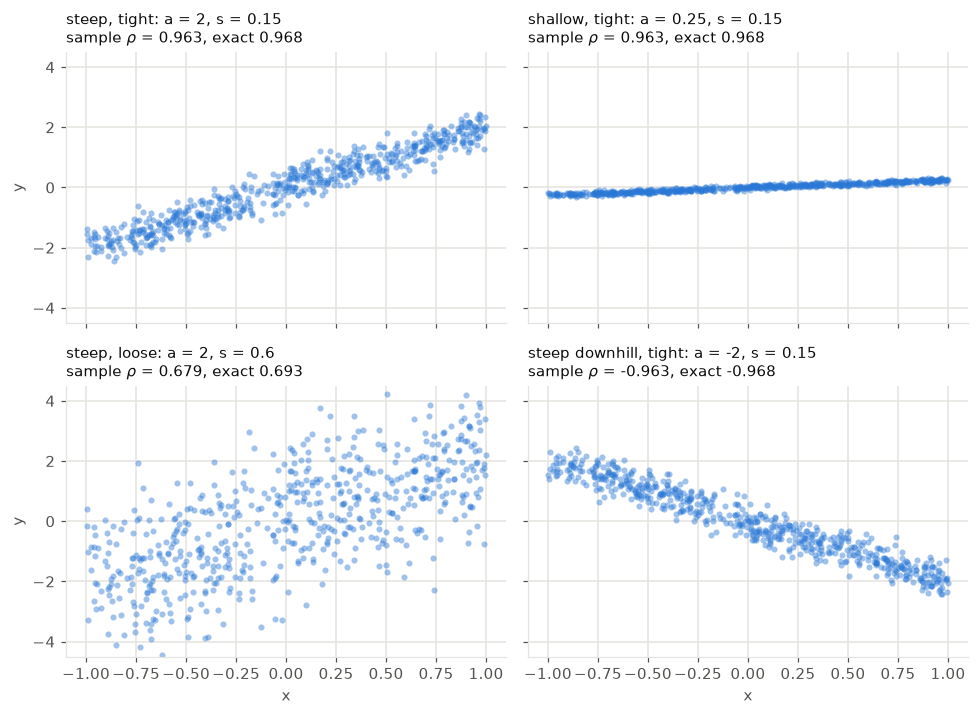

In [21]:
n_pts = 600
u_x = rng.uniform(-1, 1, size=n_pts)
noise = rng.standard_normal(n_pts)
cases = [(2, 0.15, "steep, tight"), (0.25, 0.15, "shallow, tight"),
         (2, 0.6, "steep, loose"), (-2, 0.15, "steep downhill, tight")]

fig, axes = plt.subplots(2, 2, figsize=(9, 6.6), sharex=True, sharey=True)
for ax, (a_, s_, label) in zip(axes.flat, cases):
    u_y = a_ * (u_x + s_ * noise)
    exact = np.sign(a_) / sqrt(1 + 3 * s_ ** 2)
    ax.plot(u_x, u_y, "o", color=BLUE, ms=4, alpha=0.45, mec="none")
    ax.set(xlim=(-1.1, 1.1), ylim=(-4.5, 4.5))
    ax.set_title(f"{label}: a = {a_}, s = {s_}\nsample $\\rho$ = {np.corrcoef(u_x, u_y)[0, 1]:.3f}, exact {exact:.3f}",
                 color=INK, loc="left", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

The two tight clouds on top have very different slopes but the same correlation, about $0.968$. They are built from the same points: the second cloud is the first one squashed vertically by a factor of 8, which is why even their sample correlations agree exactly. Loosening the cloud (bottom left) drops it to about $0.69$ without changing the slope. Reversing the slope (bottom right) only flips the sign.

## Common pitfalls

1. **Dropping the square, or keeping the shift.** $V(aX + b) = a^2 V(X)$, not $a V(X) + b$. In particular, $V(-X) = V(X)$ and $V(X + 100) = V(X)$.
2. **Adding the variances of dependent variables.** $V(X + Y) = V(X) + V(Y)$ needs $\mathrm{Cov}(X, Y) = 0$. For the running table, the naive answer $0.46$ misses $2\,\mathrm{Cov} = 0.30$.
3. **Subtracting variances.** For independent variables, $V(X - Y) = V(X) + V(Y)$: a difference is as uncertain as a sum.
4. **Adding standard deviations.** Stds do not add, even for independent variables. Add the variances, then take the square root.
5. **Treating zero covariance as independence.** Uncorrelated variables can be completely dependent: $Y = X^2$ with $X$ uniform on $\lbrace -1, 0, 1 \rbrace$, or the diamond. Only the direction independent $\Rightarrow$ uncorrelated holds.
6. **Using $1/25$ as the element probability of a uniform distribution over a support.** It is $1/\lvert S \rvert$. Marginals count support points in a row or column, and they are usually not uniform.
7. **Reading the size of a covariance as strength.** A covariance has units and changes with them; compare correlations instead. And $\lvert \rho \rvert$ measures how close the points are to a line, not the slope of the line.
8. **Rounding before subtracting.** $E[X^2] - \mu^2$ subtracts two numbers that can be close, so keep exact fractions. A negative "variance" or a $\lvert \rho \rvert > 1$ always signals an arithmetic error.

## Key takeaways

- **Variance** $V(X) = E[(X - \mu)^2] = E[X^2] - \mu^2 \ge 0$ measures spread, and it is 0 only for a constant. The **std** $\sigma_X = \sqrt{V(X)}$ is in the units of $X$. Fair die: $V = 35/12$.
- **Bernoulli:** $V = pq$, largest ($1/4$) at $p = 1/2$. $B_{0.75}$: $V = 3/16$.
- **Affine maps:** $E[aX + b] = aE[X] + b$, $V(aX + b) = a^2 V(X)$, $\sigma_{aX + b} = \lvert a \rvert\, \sigma_X$.
- **Joint PMF** $p(x, y)$: nonnegative, sums to 1. Marginals are row and column sums, and they do not determine the joint. Uniform over $S$: each point has probability $1/\lvert S \rvert$.
- **Covariance** $\mathrm{Cov}(X, Y) = E[(X - \mu_X)(Y - \mu_Y)] = E[XY] - \mu_X \mu_Y$ is symmetric, shift invariant, and bilinear, with $\mathrm{Cov}(X, X) = V(X)$ and $\mathrm{Cov}(aX + b, cY + d) = ac\,\mathrm{Cov}(X, Y)$. Running table: $0.15$.
- **Independent $\Rightarrow$ uncorrelated** ($\mathrm{Cov} = 0$); the converse fails in general.
- **Variance of a sum:** $V(X + Y) = V(X) + V(Y) + 2\,\mathrm{Cov}(X, Y)$, so variances add when the covariance is 0. Running table: $0.76$.
- **Correlation** $\rho = \mathrm{Cov}(X, Y)/(\sigma_X \sigma_Y)$ is unit free, $\rho_{aX+b,\, cY+d} = \mathrm{sign}(ac)\,\rho_{X,Y}$, and $\lvert \rho \rvert \le 1$, with equality exactly for a linear relation. Running table: $\sqrt{3/7} \approx 0.655$.
- Next session: families of distributions (Bernoulli, binomial, Poisson, geometric) and continuous random variables.